# Development image rotation

## TODO:
1. [x] test procedure 
1. [x] interactive method to obtain rotation angle directly in jupyter (angle in ImageJ and scikit-image appear differenr )8
1. [x] obtain rotation and post-rot-crop parameters for all sample
1. [x] also correct tilt
1. [x] distributed calculation, e.g. dask, embarassingly parallelization with joblib was sufficient
1. [x] apply to full dataset
1. [x] merge all datasets per sample and put together in new nc
1. [x] loading one set from 3+1D is much! faster than from 4D -> to be considered for 4D processing
1. [x] rotation matrix was a stupid idea, use rotation from scikit-image
1. [x] use and store new cropping
1. [ ] check different scans and make sure first scan is aligned, additional scans can be registered

**Tip: restart to kernel to not mix up sample data**


In [1]:
# modules
import xarray as xr
import json
import os
import socket
host = socket.gethostname()

import numpy as np
import cupy as cp

import scipy as sp
from scipy import ndimage
import cupyx.scipy.ndimage as cdimage

import matplotlib.pyplot as plt

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    # toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppath = '/mnt/SSD/fische_r/COELY'
    
# processing_path = os.path.join(toppath, 'processing')
# path_00_4D = os.path.join(processing_path, '00_cropped_4D') #h5 with cropped data
path_00_3p1D = os.path.join(toppath, '00_cropped_vis_in_FIJI')
    
# data overview
overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

## Interactive determination of rotation angle

In [2]:
sample = '4'

In [3]:
sample_files = []
check = sample
if sample == '3II':
    check = '3b'
for file in os.listdir(path_00_3p1D):
        if file.split('_')[2] == sample or file.split('_')[2] == check:
            sample_files.append(os.path.join(path_00_3p1D, file))

In [4]:
sample_files

['/mnt/SSD/fische_r/COELY/00_cropped_vis_in_FIJI/00_T_4_scan_01_cropped_3Dp1D.nc',
 '/mnt/SSD/fische_r/COELY/00_cropped_vis_in_FIJI/00_T_4_scan_02_cropped_3Dp1D.nc',
 '/mnt/SSD/fische_r/COELY/00_cropped_vis_in_FIJI/00_T_4_scan_03_cropped_3Dp1D.nc']

In [15]:
# select first! operando scan
data = xr.open_dataset(sample_files[1])
im = data['image_data_04'].data
data.close()

In [16]:
# define image display range
immin = 10289
immax = 14591

4,4


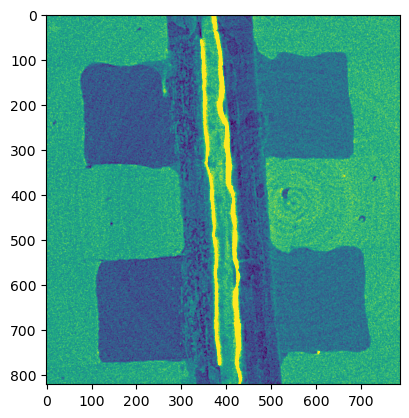

In [17]:
plt.imshow(im[:,:,500], vmin=immin, vmax=immax)
print(data.attrs['name']+','+sample)

In [18]:
test = im[:,:,500].copy()

In [31]:
rotangle = -4.5
testrot = sp.ndimage.rotate(test, rotangle)

4,4


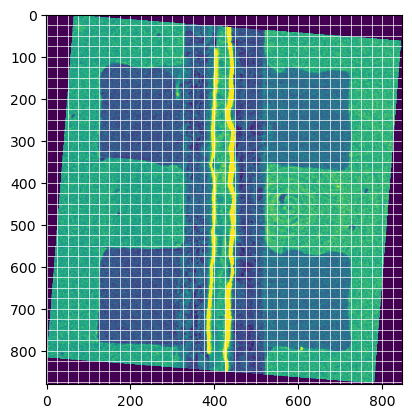

In [32]:
plt.imshow(testrot, vmin=immin, vmax=immax)
spacing = 25
grid_0 = np.arange(0,testrot.shape[0],spacing)
grid_1 = np.arange(0,testrot.shape[1],spacing)
plt.hlines(grid_0, 0, testrot.shape[1]-1, 'w', linewidth = 0.5)
plt.vlines(grid_1, 0, testrot.shape[0]-1, 'w', linewidth = 0.5)
print(data.attrs['name']+','+sample)

### new cropping for rotated image

4,4


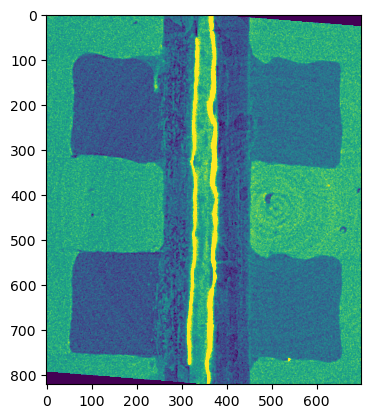

In [66]:
a = 30  #pyplot y from top
b = testrot.shape[0]-30#pyplot y from bottom
c = 70 #pyplot x from left
d = testrot.shape[1]-80 #pyplot x from right
e = 0
f = im.shape[2]

plt.imshow(testrot[a:b,c:d], vmin=immin, vmax=immax)
print(data.attrs['name']+','+sample)

### rotate one entire time step and test cropping in a few slices

In [34]:
imrot = sp.ndimage.rotate(im, rotangle)

4,4


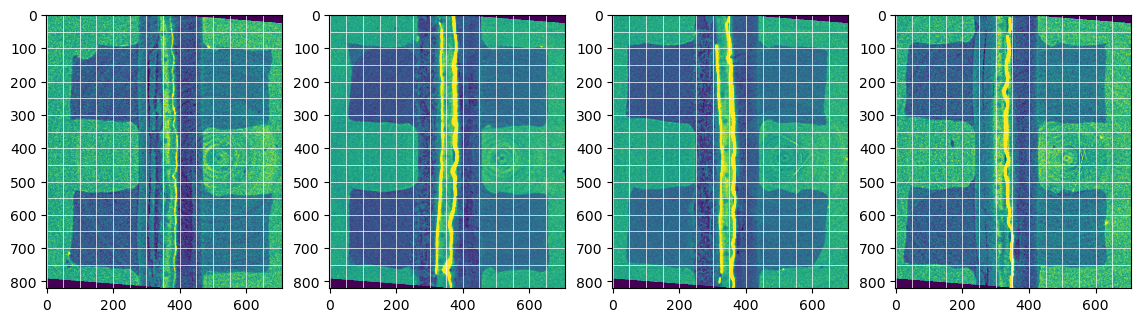

In [40]:
showgrid = True
fig, axs = plt.subplots(1,4, figsize=(14,14))
axs[0].imshow(imrot[a:b,c:d,100], vmin=immin, vmax=immax)
axs[1].imshow(imrot[a:b,c:d,700], vmin=immin, vmax=immax)
axs[2].imshow(imrot[a:b,c:d,1500], vmin=immin, vmax=immax)
axs[3].imshow(imrot[a:b,c:d,2000], vmin=immin, vmax=immax)
print(data.attrs['name']+','+sample)
if showgrid:
    spacing = 50
    grid_0 = np.arange(0,imrot[a:b,c:d,2000].shape[0]-spacing,spacing)
    grid_1 = np.arange(0,imrot[a:b,c:d,2000].shape[1]-spacing,spacing)
    for ax in axs:
        ax.hlines(grid_0, 0, imrot[a:b,c:d,2000].shape[1]-1, 'w', linewidth = 0.5)
        ax.vlines(grid_1, 0, imrot[a:b,c:d,2000].shape[0]-1, 'w', linewidth = 0.5)

### fix tilt, too

In [41]:
test2 = imrot[400,:,:].copy()

In [62]:
rotangle2 = -1.15
testrot2 = sp.ndimage.rotate(test2, rotangle2)

4,4


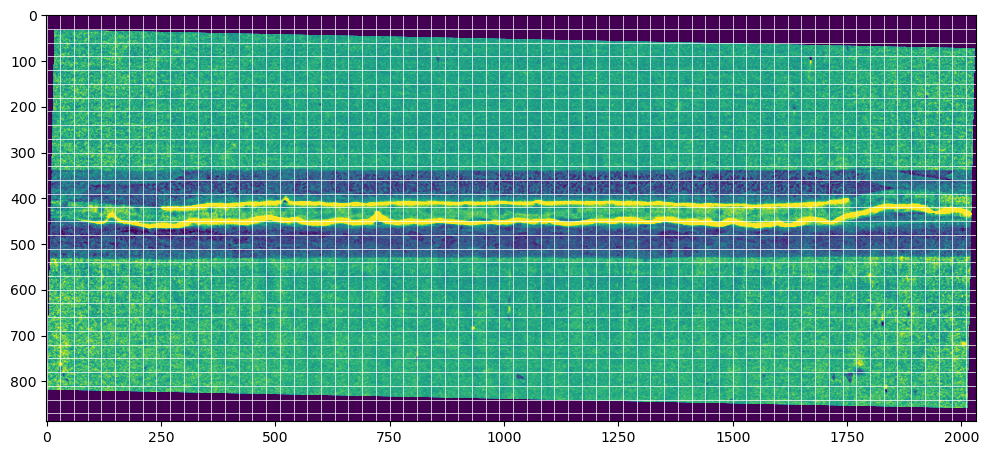

In [63]:
plt.figure(figsize=(12,12))
plt.imshow(testrot2, vmin=immin, vmax=immax)
spacing = 30
grid_0 = np.arange(0,testrot2.shape[0],spacing)
grid_1 = np.arange(0,testrot2.shape[1],spacing)
plt.hlines(grid_0, 0, testrot2.shape[1]-1, 'w', linewidth = 0.5)
plt.vlines(grid_1, 0, testrot2.shape[0]-1, 'w', linewidth = 0.5)
print(data.attrs['name']+','+sample)

### rotate entire stack, review cropping and adapt if necessary

In [64]:
imrot2 = sp.ndimage.rotate(imrot, rotangle2, axes=(2,1))

4,4


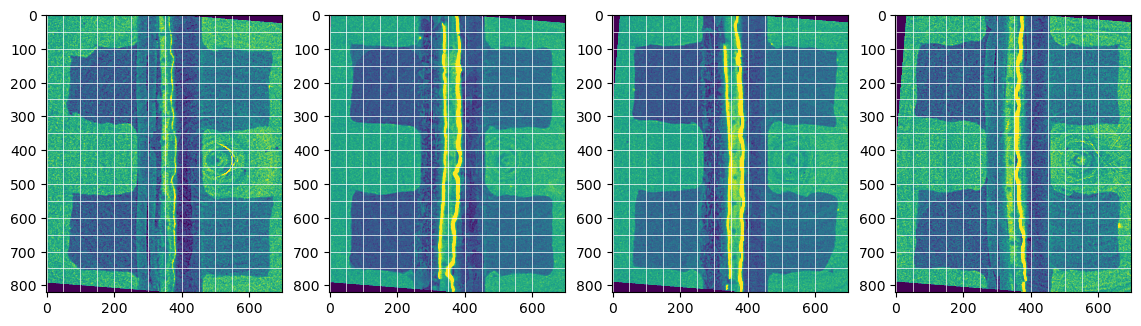

In [67]:
showgrid = True
fig, axs = plt.subplots(1,4, figsize=(14,14))
axs[0].imshow(imrot2[a:b,c:d,100], vmin=immin, vmax=immax)
axs[1].imshow(imrot2[a:b,c:d,700], vmin=immin, vmax=immax)
axs[2].imshow(imrot2[a:b,c:d,1500], vmin=immin, vmax=immax)
axs[3].imshow(imrot2[a:b,c:d,2000], vmin=immin, vmax=immax)
print(data.attrs['name']+','+sample)
if showgrid:
    spacing = 50
    grid_0 = np.arange(0,imrot2[a:b,c:d,2000].shape[0]-spacing,spacing)
    grid_1 = np.arange(0,imrot2[a:b,c:d,2000].shape[1]-spacing,spacing)
    for ax in axs:
        ax.hlines(grid_0, 0, imrot2[a:b,c:d,2000].shape[1]-1, 'w', linewidth = 0.5)
        ax.vlines(grid_1, 0, imrot2[a:b,c:d,2000].shape[0]-1, 'w', linewidth = 0.5)

### save parameters to file for later

In [68]:
#save parameters
rotdict = {'sample': sample, 'angle1': rotangle,'angle2': rotangle2, 'crop_after_rot': [a,b,c,d,e,f]}
rot_info_path = os.path.join(gitpath,'data_analysis', 'image_rotation_parameter', ''.join(['rot_params_',sample,'.json']))
with open(rot_info_path, "w") as outfile:
    json.dump(rotdict, outfile,indent = 4)

## Apply to full data set (or collect parameters and script it for ra)

In [32]:
data

<xarray.Dataset>
Dimensions:        (x: 864, y: 762, z: 2016, t_utc: 50)
Coordinates:
  * t_utc          (t_utc) float64 1.667e+09 1.667e+09 ... 1.667e+09 1.667e+09
  * x              (x) int64 0 1 2 3 4 5 6 7 ... 856 857 858 859 860 861 862 863
  * y              (y) int64 0 1 2 3 4 5 6 7 ... 754 755 756 757 758 759 760 761
  * z              (z) int64 0 1 2 3 4 5 6 ... 2010 2011 2012 2013 2014 2015
Data variables: (12/55)
    image_data_00  (x, y, z) uint16 ...
    time           (t_utc) float64 ...
    x_m            (x) float64 ...
    y_m            (y) float64 ...
    z_m            (z) float64 ...
    filenames      (t_utc, z) object ...
    ...             ...
    image_data_44  (x, y, z) uint16 ...
    image_data_45  (x, y, z) uint16 ...
    image_data_46  (x, y, z) uint16 ...
    image_data_47  (x, y, z) uint16 ...
    image_data_48  (x, y, z) uint16 ...
    image_data_49  (x, y, z) uint16 ...
Attributes:
    name:                            7x
    foldername:                      T_7x_scan_04
    scan_#:                          04
    voxel size:                      2.75 um
    voxel:                           2.75e-06
    crop coordinates [a:b,c:d,e:f]:  [ 603 1467  282 1044    0 2016]
    cropping:git_sha:                566fb36
    githash:                         566fb36820c8cea5d7127211734fe89f122108a3